<a href="https://colab.research.google.com/github/Shafeek-Bakhach/zero_to_hero_nn/blob/main/L1_micrograd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
class Value:
  def __init__(self, data, _children=(), _op='', label = ''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    return out

  def __neg__(self): # -self
    return self.data * -1

  def __sub__(self, other): # self + (-other)
    return self + (-other)

  def __truediv__(self,other):
    return self * other**-1

  def __pow__(self,other):
    assert isinstance(other, (int, float)), "only supporting ints/floats for now"
    out = Value(self.data ** other, (self, ), f'**{other}')
    def _backward():
      self.grad += out.grad * other * self.data**(other-1)
    out._backward = _backward
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
    return out

  def __rmul__(self, other):
    return self * other

  def __radd__(self, other):
    return self + other

  def __rsub__(self, other):
    return other + (-self)

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    return out

  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')
    def _backward():
      self.grad += math.exp(x) * out.grad
    out._backward = _backward
    return out


  def backward(self):
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [3]:
a = Value(2.0)
b = Value(4.0)
c = 2.0
a - c

Value(data=0.0)

In [4]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

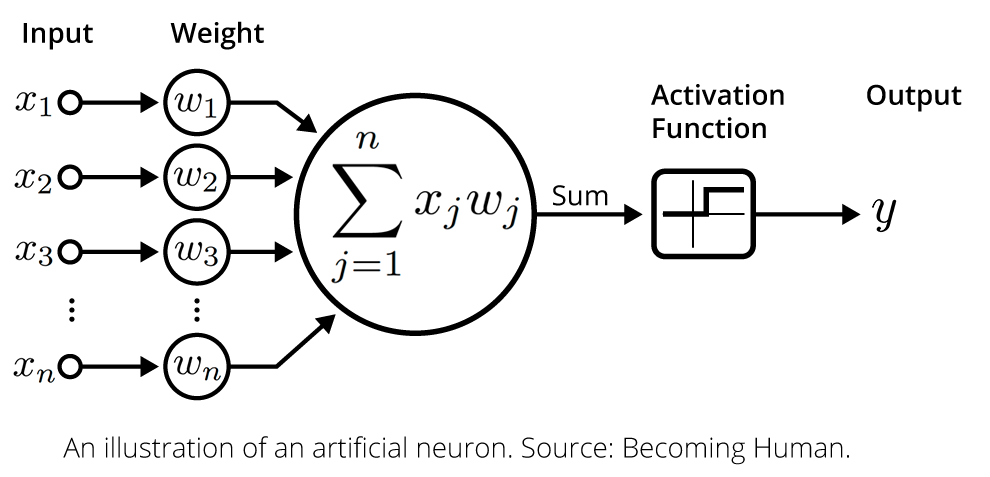

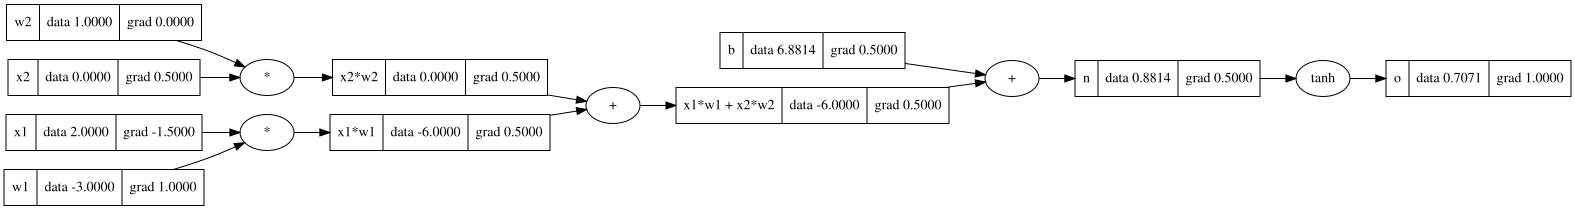

In [5]:
# inputs x1, x2
x1 = Value(2.0, label = 'x1')
x2 = Value(0.0, label = 'x2')
w1 = Value(-3.0, label = 'w1')
w2 = Value(1.0, label = 'w2')
b = Value(6.8813735870195432, label = 'b') # bias variable

x1w1 = x1*w1; x1w1.label = 'x1*w1' # first input times the weight
x2w2 = x2*w2; x2w2.label = 'x2*w2' # second input times the weight

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2' # sum of the weighted inputs

n = x1w1x2w2 + b; n.label = 'n' # add the bias to the sum, no activation function yet

o = n.tanh(); o.label = 'o' # output that has been dampened/squashed
o.backward()
draw_dot(o)

# in neural networks, we care the most about the partial derivates of the weights because those are the values we can directly tweak (vs the input data that is static)




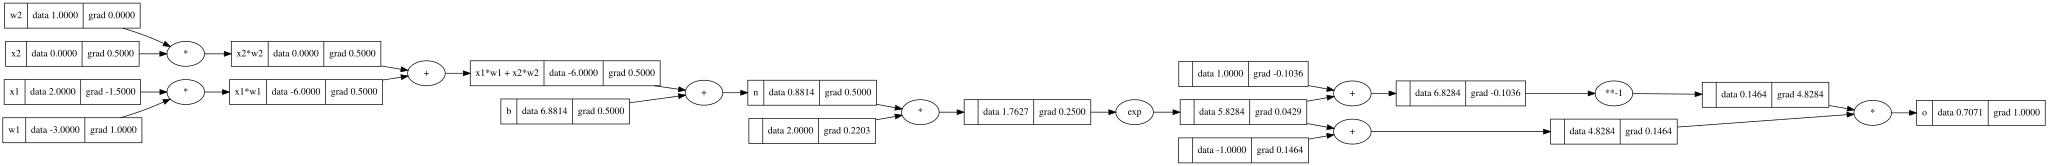

In [6]:
# inputs x1, x2
x1 = Value(2.0, label = 'x1')
x2 = Value(0.0, label = 'x2')
w1 = Value(-3.0, label = 'w1')
w2 = Value(1.0, label = 'w2')
b = Value(6.8813735870195432, label = 'b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'

n = x1w1x2w2 + b; n.label = 'n'
# --------------
e = (2*n).exp()
o = (e-1)/(e+1); o.label = 'o' # implementing tanh through atomic operations
# --------------
o.backward()
draw_dot(o)




In [8]:
# PyTorch approach
import torch
x1 = torch.tensor([2.0], dtype=torch.double); x1.requires_grad = True
w1 = torch.tensor([-3.0], dtype=torch.double); w1.requires_grad = True
x2 = torch.tensor([0.0], dtype=torch.double); x2.requires_grad = True
w2 = torch.tensor([1.0], dtype=torch.double); w2.requires_grad = True
b = torch.tensor([6.8813735870195432], dtype=torch.double); b.requires_grad = True

x1w1 = x1 * w1
x2w2 = x2 * w2

x1w1x2w2 = x1w1 + x2w2

n = x1w1x2w2 + b

o = torch.tanh(n)
o.backward()

print('---- LEAF GRADS ----')
print('x1:', x1.grad.item())
print('w1:', w1.grad.item())
print('x2:', x2.grad.item())
print('w2:', w2.grad.item())



---- LEAF GRADS ----
x1: -1.4999999999999998
w1: 0.9999999999999999
x2: 0.49999999999999994
w2: 0.0


In [9]:
# Building a MLP from scratch
import random

class Neuron:
  # initialize random weights
  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))
  # pass through activation fx
  def __call__(self, x):
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

class Layer:
  # layer consists of nin neurons
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  # populate the neurons with the random weights
  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  def __init__(self, nin, nouts): # nin is inputs (X), nouts is a list that defines the number of neurons per layer
    sz = [nin] + nouts # first element is the number of inputs
    #print('sz:', sz)
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))] # iterate over consecutive pairs

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x # return the final output node

In [46]:
# simple example of three inputs, two layers of 4, then one output neuron
l = MLP(3, [4, 4, 1])
# four rows of input data
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
# their labels
ys = [1.0, -1.0, -1.0, 1.0]


In [47]:
for k in range(25):
  # forward pass
  ypred = [l(x) for x in xs]
  loss = sum((ypr - ygt)**2 for ygt, ypr in zip(ys, ypred))
  # backward pass
  loss.backward()
  # update
  step_size = 0.05
  for p in l.parameters():
    p.data += -1 * step_size * p.grad
    p.grad = 0.0
  print(k, loss)


0 Value(data=3.030967058210702)
1 Value(data=1.2194483021853824)
2 Value(data=0.5405423768519231)
3 Value(data=0.2591345462149944)
4 Value(data=0.17604278298995693)
5 Value(data=0.13274944726913004)
6 Value(data=0.10604734155242428)
7 Value(data=0.08808943234924572)
8 Value(data=0.07523773054844077)
9 Value(data=0.06560676067889533)
10 Value(data=0.058130427927540085)
11 Value(data=0.05216341485123957)
12 Value(data=0.04729332993257376)
13 Value(data=0.043244783495008515)
14 Value(data=0.039827077821236324)
15 Value(data=0.03690408456138462)
16 Value(data=0.03437608729491561)
17 Value(data=0.03216840294151996)
18 Value(data=0.030224009143907576)
19 Value(data=0.028498626798775715)
20 Value(data=0.026957355823802397)
21 Value(data=0.025572321387988803)
22 Value(data=0.02432099395972166)
23 Value(data=0.023184968702033924)
24 Value(data=0.022149064265981608)


In [48]:
ypred
# not bad!

[Value(data=0.9403137329246787),
 Value(data=-0.9225810647594201),
 Value(data=-0.899576379720296),
 Value(data=0.9499198767500743)]